# Titanic - Machine Learning from Disaster

## Import Libraries

In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

## Fetch the data

In [2]:
train = pd.read_csv('Data/train.csv')
test  = pd.read_csv('Data/test.csv')
combined_data = [train,test]
print(train.shape,test.shape)

(891, 12) (418, 11)


In [3]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [5]:
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [6]:
# We have a lot of missing in the Age and cabins
train.isnull().sum(axis = 0)

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [7]:
train.Survived.value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

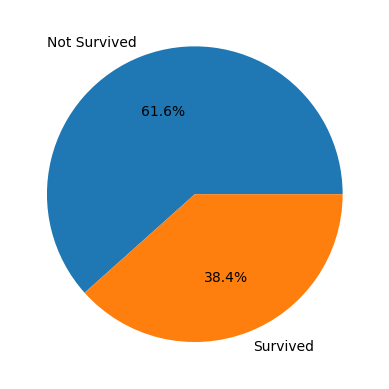

In [8]:
# The Not survived is the most so we have imbalance data
plt.pie(train.Survived.value_counts(),autopct='%1.1f%%',labels=['Not Survived','Survived'])
plt.show()

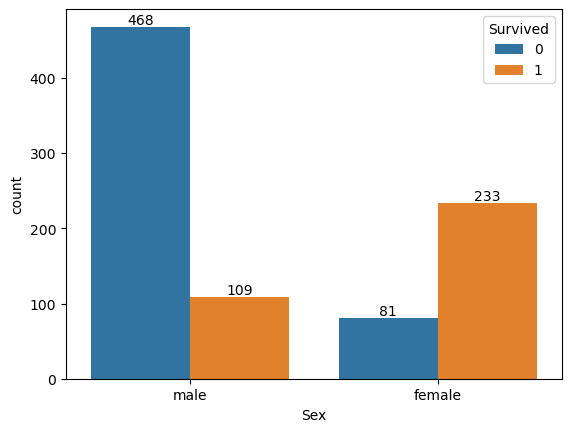

In [9]:
# The Female survived more that Male
ax = sns.countplot(data=train,x='Sex',hue='Survived')
for container in ax.containers:
    ax.bar_label(container)

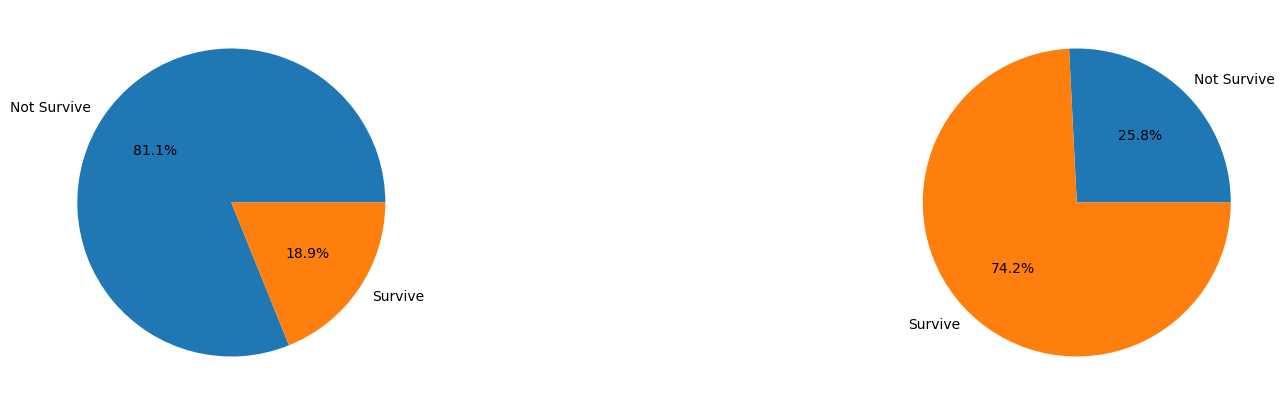

In [10]:
plt.figure(figsize=(20,5))
plt.subplot(1,2,1)
plt.pie(train[train['Sex'] == 'male'].Survived.value_counts().sort_index(),autopct='%1.1f%%',labels=['Not Survive','Survive'])
plt.subplot(1,2,2)
plt.pie(train[train['Sex'] == 'female'].Survived.value_counts().sort_index(),autopct='%1.1f%%',labels=['Not Survive','Survive'])
plt.show()

## Preprocessing & Feature Engineering

In [11]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [12]:
for dataset in combined_data:
    dataset['Cabin_Count'] = dataset.Cabin.apply(lambda x: len(x.split()) if pd.notna(x) else 0)
    dataset.drop(columns=['Ticket','Cabin'],inplace=True)

In [13]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked,Cabin_Count
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,7.2500,S,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,71.2833,C,1
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,7.9250,S,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,53.1000,S,1
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,8.0500,S,0


In [14]:
for dataset in combined_data:
    dataset['Name_Title'] = dataset.Name.apply(lambda x: x.split(',')[1].split('.')[0].strip() if x else 'Unknown')

In [15]:
pd.crosstab(train.Name_Title,train.Sex)

Sex,female,male
Name_Title,,
Capt,0,1
Col,0,2
Don,0,1
Dr,1,6
Jonkheer,0,1
Lady,1,0
Major,0,2
Master,0,40
Miss,182,0


In [16]:
for datasets in combined_data:
    datasets.Name_Title = datasets.Name_Title.replace(['Lady','the Countess','Sir','Don','Jonkheer','Dona'],'Royal')
    datasets.Name_Title = datasets.Name_Title.replace(['Col','Capt','Major'],'Military')
    datasets.Name_Title = datasets.Name_Title.replace(['Mlle','Ms'],'Miss')
    datasets.Name_Title = datasets.Name_Title.replace(['Mme'],'Mrs')

In [17]:
test.Name.apply(lambda x: x.split(',')[1].split('.')[0].strip() if x else 'Unknown').value_counts()

Name
Mr        240
Miss       78
Mrs        72
Master     21
Col         2
Rev         2
Ms          1
Dr          1
Dona        1
Name: count, dtype: int64

In [18]:
test.Name_Title.value_counts()

Name_Title
Mr          240
Miss         79
Mrs          72
Master       21
Military      2
Rev           2
Dr            1
Royal         1
Name: count, dtype: int64

In [19]:
train[['Name_Title','Survived']].groupby('Name_Title').mean()

,Survived
Name_Title,
Dr,0.428571
Master,0.575000
Military,0.400000
Miss,0.702703
Mr,0.156673
Mrs,0.793651
Rev,0.000000
Royal,0.600000


In [20]:
titles_median = train.groupby('Name_Title')['Age'].median()
for dataset in combined_data:
    dataset.Age.fillna(dataset.Name_Title.map(titles_median),inplace=True)

In [21]:
# Make Age groups
bins = [-1,0,5,12,20,35,60,np.inf]
labels = ['Unknown','Baby','Child','Teenager','Young Adult','Adult','Senior']
for dataset in combined_data:
    dataset.Age.fillna(-0.5,inplace=True)
    dataset['Age_Group'] = pd.cut(dataset.Age,bins,labels=labels)



In [22]:
train.Age_Group.value_counts()

Age_Group
Young Adult    490
Adult          196
Teenager       110
Baby            48
Child           25
Senior          22
Unknown          0
Name: count, dtype: int64

In [23]:
for dataset in combined_data:
    dataset['FareBand'] = pd.qcut(dataset.Fare, 4 , labels=[1,2,3,4])

In [24]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked,Cabin_Count,Name_Title,Age_Group,FareBand
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,7.2500,S,0,Mr,Young Adult,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,71.2833,C,1,Mrs,Adult,4
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,7.9250,S,0,Miss,Young Adult,2
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,53.1000,S,1,Mrs,Young Adult,4
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,8.0500,S,0,Mr,Young Adult,2


In [25]:
for dataset in combined_data:
    dataset.Sex = dataset.Sex.map({'male':0,'female':1})

In [26]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked,Cabin_Count,Name_Title,Age_Group,FareBand
0,1,0,3,"Braund, Mr. Owen Harris",0,22.0,1,0,7.2500,S,0,Mr,Young Adult,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,1,0,71.2833,C,1,Mrs,Adult,4
2,3,1,3,"Heikkinen, Miss. Laina",1,26.0,0,0,7.9250,S,0,Miss,Young Adult,2
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,1,0,53.1000,S,1,Mrs,Young Adult,4
4,5,0,3,"Allen, Mr. William Henry",0,35.0,0,0,8.0500,S,0,Mr,Young Adult,2


In [27]:
for dataset in combined_data:
    dataset.drop(columns=['Name','Fare','Age'],inplace=True)

In [28]:
train.head()

,PassengerId,Survived,Pclass,Sex,SibSp,Parch,Embarked,Cabin_Count,Name_Title,Age_Group,FareBand
0,1,0,3,0,1,0,S,0,Mr,Young Adult,1
1,2,1,1,1,1,0,C,1,Mrs,Adult,4
2,3,1,3,1,0,0,S,0,Miss,Young Adult,2
3,4,1,1,1,1,0,S,1,Mrs,Young Adult,4
4,5,0,3,0,0,0,S,0,Mr,Young Adult,2


In [29]:
train = pd.get_dummies(train,columns=['Name_Title','Embarked','Age_Group'],drop_first=True,dtype=np.int64)
test = pd.get_dummies(test,columns=['Name_Title','Embarked','Age_Group'],drop_first=True,dtype=np.int64)

## Make and Evaluate the Model

In [38]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

X = train.drop(['Survived','PassengerId'], axis=1)
y = train["Survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [39]:
def Evaluation_Metrics(Target,Predicted):
    TP = np.sum((Target == 1)&(Predicted == 1))
    TN = np.sum((Target == 0)&(Predicted == 0))
    FP = np.sum((Target == 0)&(Predicted == 1))
    FN = np.sum((Target == 1)&(Predicted == 0))
    print(f'True Postive {TP},True Negative {TN},False Positive {FP},False Negative {FN}')
    Accuracy = (TP + TN)/(TP + TN + FP+ FN) * 100
    Recall   = TP / (TP + FN) * 100
    Percision= TP / (TP + FP) * 100
    F1_score = 2 * ((Percision * Recall)/(Percision + Recall)) 
    print(f'Accuracy  = {Accuracy:.2f}\nRecall    = {Recall:.2f}\nPercision = {Percision:.2f}\nF1-score  = {F1_score:.2f}')

In [46]:
Forest_Model = RandomForestClassifier(n_estimators=500,max_depth=6,min_samples_leaf=5)
Forest_Model.fit(X_train,y_train)
preds = Forest_Model.predict(X_test)
Evaluation_Metrics(y_test,preds)

True Postive 52,True Negative 94,False Positive 16,False Negative 17
Accuracy  = 81.56
Recall    = 75.36
Percision = 76.47
F1-score  = 75.91


In [51]:
ids = test.PassengerId
test_preds = Forest_Model.predict(test.drop(columns=['PassengerId']))
output = pd.DataFrame({'PassengerId':ids,'Survived':test_preds})
output.to_csv('predictionFile.csv',index=False)